# FlameGPU development

In [35]:
# check if pyflamegpu is installed and if not install it
import importlib.util
if importlib.util.find_spec('pyflamegpu') is None:
    import sys
    !{sys.executable} -m pip install --extra-index-url https://whl.flamegpu.com/whl/cuda130/ pyflamegpu

# Import pyflamegpu and some other libraries we will use in the tutorial
import pyflamegpu
import pyflamegpu.codegen
import sys, random, math
import numpy as np
import matplotlib.pyplot as plt
import importlib

#set matplotlib backend to widget for some advanced plotting tools
%matplotlib widget

# import
import visualiser

# reload local modules
importlib.reload(visualiser)

<module 'visualiser' from 'c:\\Users\\yhmg1v\\OneDrive - Personal\\OneDrive\\Google Drive\\10 Coding Models\\04 Housing UBDC\\FlameGPU\\visualiser.py'>

## Model parameters

In [36]:
# Model Parameters
DIM = 500               # Dimensions of our 2D grid
SIMULATION_STEPS = 150  # Number of time steps
DENSITY = 0.8           # Density of houses
OCCUPANCY = 0.8         # Occupancy rate at initialisation
CAPITAL = [300000, 300001]
PRICE = [200000, 200001]


# Global parameters
INTEREST = 3.7
LTV = 90
CAPITAL_THRESHOLD = 200000

## Create model and agents

Include message dependencies

In [37]:
def create_model():
    model = pyflamegpu.ModelDescription("housing")
    return model

def define_environment(model):
    env = model.Environment()

    # Env properties
    env = model.Environment()
    env.newPropertyFloat("INTEREST", INTEREST)
    env.newPropertyInt("LTV", LTV)
    env.newPropertyInt("CAPITAL_THRESHOLD", CAPITAL_THRESHOLD)
    env.newPropertyInt("ID_COUNTER", 0)

def define_agents(model):
    """
    House agent
    """
    ## House
    h = model.newAgent("house")
    print("define_agents")
    print(type(h))
    h.newVariableInt("constructed?")
    h.newVariableInt("x")
    h.newVariableInt("y")
    h.newVariableInt("my_owner")    # ID of the household
    h.newVariableInt("price")
    h.newVariableInt("offered_to")  # ID of the household who made an offer
    h.newVariableInt("for_sale?")   # 0 or 1
    h.newVariableInt("for_rent?")   # 0 or 1
    h.newVariableInt("offer_confirmed?")
    h.newVariableInt("id")

    ## Households
    hh = model.newAgent("household")
    hh.newVariableInt("x")
    hh.newVariableInt("y")        
    hh.newVariableInt("income")
    hh.newVariableInt("capital")   
    hh.newVariableInt("my_house")        # ID of the house
    hh.newVariableInt("on_market?")      # 0 or 1, on the mortgage market or not
    hh.newVariableInt("move?")          # Whether the agent should physically move or not
    hh.newVariableInt("move_x")
    hh.newVariableInt("move_y")
    hh.newVariableInt("move_h")
    hh.newVariableInt("active?")         # True or False
    hh.newVariableInt("made_offer_on")
    hh.newVariableInt("monitor_id")
    hh.newVariableInt("id")
    hh.newVariableFloat("new_rand")
    hh.newVariableFloat("current_rand")

    return h, hh

def define_model_functions(model):
    h = model.Agent("house")
    hh = model.Agent("household")
    print("define_model_functions")
    print(type(h))  

    # Function 0.1
    hh_message_location_fn = hh.newRTCFunction(
        "hh_message_location", pyflamegpu.codegen.translate(hh_message_location)
    )
    hh_message_location_fn.setMessageOutput("hh_message_location")

    # Function 0.2
    h_update_owner_fn = h.newRTCFunction(
        "h_update_owner", pyflamegpu.codegen.translate(h_update_owner)
    )
    h_update_owner_fn.setMessageInput("hh_message_location")
    h_update_owner_fn.setMessageOutput("h_update_owner")

    # Function 0.3
    hh_update_ownership_fn = hh.newRTCFunction(
        "hh_update_ownership", pyflamegpu.codegen.translate(hh_update_ownership)
    )
    hh_update_ownership_fn.setMessageInput("h_update_owner")

    # Function 1
    hh_market_participation_fn = hh.newRTCFunction(
        "hh_market_participation", pyflamegpu.codegen.translate(hh_market_participation)
    )

    # Function 6
    hh_move_fn = hh.newRTCFunction(
        "hh_move", pyflamegpu.codegen.translate(hh_move)
    )
    # hh_move_fn.setMessageInput("h_recieve_offer") ## Write the messages!
    hh_move_fn.setMessageOutput("hh_move")

    # Function 7
    h_move_fn = h.newRTCFunction(
        "h_move", pyflamegpu.codegen.translate(h_move)
    )
    h_move_fn.setMessageInput("hh_move") ## Write the messages!

    

def define_submodel_functions(submodel):
    h = submodel.Agent("house")
    hh = submodel.Agent("household")

    # Function 2
    h_put_on_market_fn = h.newRTCFunction(
        "h_put_on_market", pyflamegpu.codegen.translate(h_put_on_market)
    )
    h_put_on_market_fn.setMessageOutput("h_put_on_market") ## Write the messages!
    h_put_on_market_fn.setMessageOutputOptional(True) ## Means that some houses may send the message and some may not

    # Function 3
    hh_make_offers_fn = hh.newRTCFunction(
        "hh_make_offers", pyflamegpu.codegen.translate(hh_make_offers)
    )
    hh_make_offers_fn.setMessageInput("h_put_on_market")
    hh_make_offers_fn.setMessageOutput("hh_make_offers")
    hh_make_offers_fn.setMessageOutputOptional(True)
    
    # Function 4
    h_recieve_offer_fn = h.newRTCFunction(
    "h_recieve_offer", pyflamegpu.codegen.translate(h_recieve_offer)
    )
    h_recieve_offer_fn.setMessageInput("hh_make_offers") ## Write the messages!
    h_recieve_offer_fn.setMessageOutput("h_recieve_offer") ## Write the messages!
    h_recieve_offer_fn.setMessageOutputOptional(True) ## Means that some houses may send the message and some may not

    # Function 5
    hh_offer_accepted_fn = hh.newRTCFunction(
        "hh_offer_accepted", pyflamegpu.codegen.translate(hh_offer_accepted)
    )
    hh_offer_accepted_fn.setMessageInput("h_recieve_offer") ## Write the messages!
    # hh_offer_accepted_fn.setMessageOutput("hh_offer_accepted") ## Write the messages!
    hh_offer_accepted_fn.setMessageOutputOptional(True) ## Means that some households may send the message and some may not
    
# def define_agents_without_functions(model):
#     """
#     House agent
#     """
#     ## House
#     h = model.newAgent("house")
#     h.newVariableInt("constructed?")
#     h.newVariableInt("x")
#     h.newVariableInt("y")
#     h.newVariableInt("my_owner")    # ID of the household
#     h.newVariableInt("price")
#     h.newVariableInt("offered_to")  # ID of the household who made an offer
#     h.newVariableInt("for-sale?")   # 0 or 1
#     h.newVariableInt("for-rent?")   # 0 or 1

#     ## Households
#     hh = model.newAgent("household")
#     hh.newVariableInt("x")
#     hh.newVariableInt("y")        
#     hh.newVariableInt("income")
#     hh.newVariableInt("capital")   
#     hh.newVariableInt("my_house")        # ID of the house
#     hh.newVariableInt("on_market?")      # 0 or 1, on the mortgage market or not
#     hh.newVariableInt("active?")         # True or False


    


    




In [38]:
## ----------------------
## Define dependencies
## ----------------------

    
def define_submodel_dependencies(submodel_model, submodel_submodel):
    h = submodel_model.Agent("house")
    hh = submodel_model.Agent("household")
    h_put_on_market_fn = h.Function("h_put_on_market")
    hh_make_offers_fn = hh.Function("hh_make_offers")
    h_recieve_offer_fn = h.Function("h_recieve_offer")
    hh_offer_accepted_fn = hh.Function("hh_offer_accepted")

    submodel_model.addExecutionRoot(h_put_on_market_fn)
    # Define dependencies
    # h_put_on_market_fn.dependsOn(hh_market_participation_fn)
    hh_make_offers_fn.dependsOn(h_put_on_market_fn)
    h_recieve_offer_fn.dependsOn(hh_make_offers_fn)
    hh_offer_accepted_fn.dependsOn(h_recieve_offer_fn)
    # hh_move_fn.dependsOn(hh_offer_accepted_fn)
    # submodel.generateLayers()

    

## One of the ways to print in agent functions
## math.printf()
## anything subceded with math. is dealt with as a c function

def define_model_dependencies(model, submodel):
    h = model.Agent("house")
    hh = model.Agent("household")
    hh_message_location_fn = hh.Function("hh_message_location")
    h_update_owner_fn = h.Function("h_update_owner")
    hh_update_ownership_fn = hh.Function("hh_update_ownership")
    hh_market_participation_fn = hh.Function("hh_market_participation")
    hh_move_fn = hh.Function("hh_move")
    h_move_fn = h.Function("h_move")
    

    model.addExecutionRoot(hh_message_location_fn)
    h_update_owner_fn.dependsOn(hh_message_location_fn)
    hh_update_ownership_fn.dependsOn(h_update_owner_fn)
    hh_market_participation_fn.dependsOn(hh_update_ownership_fn)
    submodel.dependsOn(hh_market_participation_fn)
    hh_move_fn.dependsOn(submodel)
    h_move_fn.dependsOn(hh_move_fn)

    model.generateLayers()

    


## Define messages

In [39]:
## ------------------
## Define messages
## ------------------

def define_messages(model):

    ## hh_message_location
    msg_hh_message_location = model.newMessageBruteForce("hh_message_location")
    msg_hh_message_location.newVariableInt("x")
    msg_hh_message_location.newVariableInt("y")
    msg_hh_message_location.newVariableInt("hh")

    ## h_update_owner
    msg_h_update_owner = model.newMessageBruteForce("h_update_owner")
    msg_h_update_owner.newVariableInt("h")
    msg_h_update_owner.newVariableInt("hh")

    ## hh_update_ownership

    ## hh_market participation

    ## h_put_on_market
    msg_h_put_on_market = model.newMessageBruteForce("h_put_on_market")
    msg_h_put_on_market.newVariableInt("h_ID")
    msg_h_put_on_market.newVariableInt("h_x")
    msg_h_put_on_market.newVariableInt("h_y")
    msg_h_put_on_market.newVariableInt("h_price")

    ## hh_make_offers
    msg_hh_make_offers = model.newMessageBruteForce("hh_make_offers")
    msg_hh_make_offers.newVariableInt("h_offered")
    msg_hh_make_offers.newVariableInt("h_offered_x")
    msg_hh_make_offers.newVariableInt("h_offered_y")
    msg_hh_make_offers.newVariableInt("hh_offering")

    ## h_recieve_offer
    msg_h_recieve_offer = model.newMessageBruteForce("h_recieve_offer")
    msg_h_recieve_offer.newVariableInt("h_offered_conf")
    msg_h_recieve_offer.newVariableInt("h_offered_conf_x")
    msg_h_recieve_offer.newVariableInt("h_offered_conf_y")
    msg_h_recieve_offer.newVariableInt("hh_offering_conf")

    ## hh_offer_accepted

    ## hh_move
    msg_hh_move = model.newMessageBruteForce("hh_move")
    msg_hh_move.newVariableInt("h_old")
    msg_hh_move.newVariableInt("h_new")
    msg_hh_move.newVariableInt("hh")

    ## h_move
    
    ## hh_immigration

    ## hh_emigration

    pass




## Define functions

In [40]:
## Part of a submodel
## purchasing_
## ------------------
##  Functions
## ------------------
@pyflamegpu.agent_function
def hh_message_location(message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageBruteForce):
    pyflamegpu.setVariableInt("id", -90)
    message_out.setVariableInt("x", pyflamegpu.getVariableInt("x"))
    message_out.setVariableInt("y", pyflamegpu.getVariableInt("y"))
    message_out.setVariableInt("hh", pyflamegpu.getID())

@pyflamegpu.agent_function
def h_update_owner(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageBruteForce):
    for message in message_in:
        if message.getVariableInt("x") == pyflamegpu.getVariableInt("x") and message.getVariableInt("y") == pyflamegpu.getVariableInt("y"):
            # pyflamegpu.setVariableInt("for_rent?", message.getVariableInt("hh"))
            pyflamegpu.setVariableInt("my_owner", message.getVariableInt("hh"))
            message_out.setVariableInt("h", pyflamegpu.getID())
            message_out.setVariableInt("hh", message.getVariableInt("hh"))

@pyflamegpu.agent_function
def hh_update_ownership(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageNone):
    for message in message_in:
        if message.getVariableInt("hh") == pyflamegpu.getID():
            pyflamegpu.setVariableInt("id", message.getVariableInt("h"))
            pyflamegpu.setVariableInt("my_house", message.getVariableInt("h"))

@pyflamegpu.agent_function
def hh_market_participation(message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageNone):
    """
    Put the household on the housing market if their capital are high
    """
    ## If I have high capital, go on the market
    pyflamegpu.setVariableInt("active?", False)
    # pyflamegpu.setVariableInt("id", pyflamegpu.getID())
    if pyflamegpu.getVariableInt("capital") > pyflamegpu.environment.getPropertyInt("CAPITAL_THRESHOLD"):
        # pyflamegpu.setVariableInt("id", -7)
        pyflamegpu.setVariableInt("on_market?", True)
        pyflamegpu.setVariableInt("active?", True)
    
    # print(pyflamegpu.getVariableInt("monitor_id"))
    return pyflamegpu.ALIVE

@pyflamegpu.agent_function
def h_put_on_market(message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageBruteForce):
    """
    If the house is vacant, put it on the market
    """
    if pyflamegpu.getVariableInt("constructed?") == True and pyflamegpu.getVariableInt("offer_confirmed?") == False:
        ## If the house is vacant, put it for sale
        if pyflamegpu.getVariableInt("my_owner") == 0:
            pyflamegpu.setVariableInt("for_sale?", True)

            ## Report the house's ID
            # message_out.setIndex(pyflamegpu.getVariableInt("x"), pyflamegpu.getVariableInt("y"))
            message_out.setVariableInt("h_ID", pyflamegpu.getID())
            message_out.setVariableInt("h_x", pyflamegpu.getVariableInt("x"))
            message_out.setVariableInt("h_y", pyflamegpu.getVariableInt("y"))
            message_out.setVariableInt("h_price", pyflamegpu.getVariableInt("price"))
    return pyflamegpu.ALIVE


@pyflamegpu.agent_function
def hh_make_offers(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageBruteForce):
    """
    Make offers on vacant houses within my budget
    """
    if pyflamegpu.getVariableInt("active?") and pyflamegpu.getVariableInt("on_market?"):
        current_rand = 0.0
        h_offered = 0
        h_offered_x = 0
        h_offered_y = 0
        hh_offering = 0
        for message in message_in:
            if message.getVariableInt("h_price") <= pyflamegpu.getVariableInt("capital"):
                ## Toss a die
                new_rand = pyflamegpu.random.uniformFloat()
                ## If the die value is higher than the previous highest value, make an offer on the house
                if current_rand < new_rand:
                    h_offered = message.getVariableInt("h_ID")
                    h_offered_x = message.getVariableInt("h_x")
                    h_offered_y = message.getVariableInt("h_y")
                    hh_offering = pyflamegpu.getID()
                    # pyflamegpu.setVariableInt("active?", True)  # redundant assignment
                    pyflamegpu.setVariableFloat("current_rand", current_rand)
                    current_rand = new_rand
                    pyflamegpu.setVariableFloat("new_rand", new_rand)
                # else:
                #     pyflamegpu.setVariableInt("active?", False)

        ## If the household found a house
        if h_offered > 0:
            ## Send all the messages
            message_out.setVariableInt("h_offered", h_offered)
            message_out.setVariableInt("h_offered_x", h_offered_x)
            message_out.setVariableInt("h_offered_y", h_offered_y)
            message_out.setVariableInt("hh_offering", hh_offering)
        ## If the household found no house after going through all the messages
        else:
            ## Become inactive and send no messages
            pyflamegpu.setVariableInt("active?", False)
    return pyflamegpu.ALIVE


@pyflamegpu.agent_function
def h_recieve_offer(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageBruteForce):
    """
    Consider offers and send a confirmation for the accepted offer
    """
    if pyflamegpu.getVariableInt("constructed?") == True:
        current_rand = 0.0
        h_offered_conf = 0
        h_offered_conf_x = 0
        h_offered_conf_y = 0
        hh_offering_conf = 0
        for message in message_in:
            ## If I am the house the an offer was made upon
            if message.getVariableInt("h_offered") == pyflamegpu.getID():
                ## Randomly select an offer
                new_rand = pyflamegpu.random.uniformFloat()
                if current_rand < new_rand:
                    h_offered_conf = message.getVariableInt("h_offered")
                    h_offered_conf_x = message.getVariableInt("h_offered_x")
                    h_offered_conf_y = message.getVariableInt("h_offered_y")
                    hh_offering_conf = message.getVariableInt("hh_offering")
                    pyflamegpu.setVariableInt("offered_to", message.getVariableInt("h_offered"))
                    current_rand = new_rand
        if h_offered_conf != 0:
            pyflamegpu.setVariableInt("offer_confirmed?", True)
        message_out.setVariableInt("h_offered_conf", h_offered_conf)
        message_out.setVariableInt("h_offered_conf_x", h_offered_conf_x)
        message_out.setVariableInt("h_offered_conf_y", h_offered_conf_y)
        message_out.setVariableInt("hh_offering_conf", hh_offering_conf)
        
    return pyflamegpu.ALIVE

@pyflamegpu.agent_function
def hh_offer_accepted(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageNone):
    """
    Updates the household `made_offer_on` to confirm the move
    """
    if pyflamegpu.getVariableInt("active?"):
        for message in message_in:
            if message.getVariableInt("hh_offering_conf") == pyflamegpu.getID():
                pyflamegpu.setVariableInt("made_offer_on", message.getVariableInt("h_offered_conf"))
                # pyflamegpu.setVariableInt("x", message.getVariableInt("h_offered_conf_x"))
                # pyflamegpu.setVariableInt("y", message.getVariableInt("h_offered_conf_y"))
                pyflamegpu.setVariableInt("move?", True)
                pyflamegpu.setVariableInt("move_x", message.getVariableInt("h_offered_conf_x"))
                pyflamegpu.setVariableInt("move_y", message.getVariableInt("h_offered_conf_y"))
                pyflamegpu.setVariableInt("move_h", message.getVariableInt("h_offered_conf"))
                pyflamegpu.setVariableInt("active?", False)
    return pyflamegpu.ALIVE

## Checks chains should be added here

@pyflamegpu.agent_function
def hh_move(message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageBruteForce):
    """
    Moves the agent if it has a `made_offer_on`
    """
    if pyflamegpu.getVariableInt("move?") == True:
        # pyflamegpu.setVariableInt("id", -222)
        message_out.setVariableInt("h_old", pyflamegpu.getVariableInt("my_house"))
        message_out.setVariableInt("h_new", pyflamegpu.getVariableInt("move_h"))
        message_out.setVariableInt("hh", pyflamegpu.getID())
        
        pyflamegpu.setVariableInt("x", pyflamegpu.getVariableInt("move_x"))
        pyflamegpu.setVariableInt("y", pyflamegpu.getVariableInt("move_y"))
        pyflamegpu.setVariableInt("my_house", pyflamegpu.getVariableInt("move_h"))

        pyflamegpu.setVariableInt("move?", False)
        pyflamegpu.setVariableInt("move_x", 0)
        pyflamegpu.setVariableInt("move_y", 0)
        pyflamegpu.setVariableInt("move_h", 0)
        # pyflamegpu.setVariableInt("active?", False)

    return pyflamegpu.ALIVE

@pyflamegpu.agent_function
def h_move(message_in: pyflamegpu.MessageBruteForce, message_out: pyflamegpu.MessageNone):
    """
    Manages the house parameters after a household moves
    """
    for message in message_in:
        if message.getVariableInt("h_old") == pyflamegpu.getID():
            pyflamegpu.setVariableInt("my_owner", 0)
            pyflamegpu.setVariableInt("offered_to", 0)
            pyflamegpu.setVariableInt("for_sale?", False)
            pyflamegpu.setVariableInt("offer_confirmed?", False)
            # pyflamegpu.setVariableInt("id", -10)
        elif message.getVariableInt("h_new") == pyflamegpu.getID():
            pyflamegpu.setVariableInt("my_owner", message.getVariableInt("hh"))
            pyflamegpu.setVariableInt("offered_to", 0)
            pyflamegpu.setVariableInt("for_sale?", False)
            pyflamegpu.setVariableInt("offer_confirmed?", False)
            # pyflamegpu.setVariableInt("id", -20)

## Submodel

In [41]:
def create_submodel(model):
    active_model = pyflamegpu.ModelDescription("housing_submodel")
    # link the two models
    active_submodel = model.newSubModel("active_submodel", active_model)
    return active_model, active_submodel

def define_submodel_environment(active_model):
    define_environment(active_model)

def define_submodel_messages(active_model):
    define_messages(active_model)

def define_submodel_agents(active_model):
    define_agents(active_model)

def define_submodel_execution_order(active_model):
    # active_model.newLayer().addAgentFunction("household", "hh_market_participation")
    active_model.newLayer().addAgentFunction("house", "h_put_on_market")
    active_model.newLayer().addAgentFunction("household", "hh_make_offers")
    active_model.newLayer().addAgentFunction("house", "h_recieve_offer")
    active_model.newLayer().addAgentFunction("household", "hh_offer_accepted")
    # active_model.newLayer().addAgentFunction("household", "hh_move")
    active_model.addExitCondition(ActiveExitCondition())

def add_submodel(model):
    active_model, active_submodel = create_submodel(model)
    
    define_submodel_environment(active_model)
    define_submodel_messages(active_model)
    define_submodel_agents(active_model)
    define_submodel_functions(active_model)
    define_submodel_execution_order(active_model)

    # Note: submodel must be added to a dependency graph
    
    active_submodel.bindAgent("house", "house", True, True)
    active_submodel.bindAgent("household", "household", True, True)

    return active_model, active_submodel

# Define a host condition function
class ActiveExitCondition(pyflamegpu.HostCondition):
    def __init__(self):
        super().__init__()
        self.iterations = 0
    
    def run(self, FLAMEGPU):
        self.iterations += 1
        # Agent movements still unresolved
        
        if FLAMEGPU.agent("household").countInt("active?", True) and self.iterations < 5000:
            # print(f'Iteration {self.iterations} | active? = {FLAMEGPU.agent("household").countInt("active?", False)} | ids = {FLAMEGPU.agent("household").countInt("id", 1)}')
            return pyflamegpu.CONTINUE
        # Helpful debug statement to see how many iterations are required to resolve the conflicts
        # print(f"Conflict resolved by iteration {self.iterations}")
        self.iterations = 0
        return pyflamegpu.EXIT

## Initialise the model

In [42]:
import itertools

def initialise_population(model):
    patches_list = pyflamegpu.AgentVector(model.Agent("house"), DIM * DIM)
    i_patch = 0
    count_occupiers = 0
    id_counter = 0

    for x, y in itertools.product(range(DIM), range(DIM)):
        ## Find the patch
        patch = patches_list[i_patch]
        id_counter += 1
        patch.setVariableInt("id", id_counter)
        ## Allocate the patch's x and y variables
        patch.setVariableInt("x", x)
        patch.setVariableInt("y", y)
        ## Construct houses based on DENSITY
        if random.random() <= DENSITY:
            patch.setVariableInt("constructed?", True)
            patch.setVariableInt("price", random.randint(PRICE[0], PRICE[1]))
            ## Occupy the houses based on OCCUPANCY
            if random.random() <= OCCUPANCY:
                patch.setVariableInt("my_owner", -1)
                count_occupiers += 1
                # occupier = occupiers_list[i_occupier]
                # occupier.setVariable("my_house", patch.getID())
                # occupier.setVariable("x", x)
                # occupier.setVariable("y", y)
        ## Increment the patch index
        i_patch += 1

    occupiers_list = pyflamegpu.AgentVector(model.Agent("household"), count_occupiers)
    i_occupier = 0
    for i_patch in range(DIM * DIM):
        patch = patches_list[i_patch]
        if patch.getVariableInt("constructed?") == True and patch.getVariableInt("my_owner") == -1:
            occupier = occupiers_list[i_occupier]
            id_counter += 1
            occupier.setVariableInt("id", id_counter)
            occupier.setVariableInt("x", patch.getVariableInt("x"))
            occupier.setVariableInt("y", patch.getVariableInt("y"))
            occupier.setVariableInt("my_house", patch.getID())
            occupier.setVariableInt("capital", random.randint(CAPITAL[0], CAPITAL[1]))
            patch.setVariableInt("my_owner", occupier.getID())
            i_occupier += 1

    return patches_list, occupiers_list

    



In [43]:
def initialise_simulation():
    global model

    model = create_model()
    define_environment(model)
    define_messages(model)
    define_agents(model)
    define_model_functions(model)
    active_model, active_submodel = add_submodel(model)
    define_submodel_dependencies(active_model, active_submodel)
    define_model_dependencies(model, active_submodel)
    # define_dependencies(model)

    # h = model.Agent("house")
    # hh = model.Agent("household")
    # h_put_on_market_fn = h.Function("h_put_on_market")

    # create an initial population of agents
    init_patches, init_occupiers = initialise_population(model)

    # create a CUDA simulation and set the initial data
    cuda_simulation = pyflamegpu.CUDASimulation(model)
    cuda_simulation.setPopulationData(init_patches)
    cuda_simulation.setPopulationData(init_occupiers)

    return cuda_simulation


In [44]:
import shutil
import os

SIMULATION_STEPS = 100

def execute_simulation():
    # delete previous data
    if os.path.exists("data"):
        shutil.rmtree("data")
    os.mkdir("data")

    cuda_simulation = initialise_simulation()
    # Log the initial state
    cuda_simulation.exportData(f"data/0.json")
    # initialisation_data()
    print("Setup complete")
    # simulate for number of steps and log the complete state
    for i in range(SIMULATION_STEPS):
        cuda_simulation.step()
        cuda_simulation.exportData(f"data/{i+1}.json")
    print("Simulation complete")

import time
# start = timeit.timeit()
# execute_simulation()
# end = timeit.timeit()
# print(end - start)

start = time.time()
execute_simulation()
end = time.time()

print(f"Execution time: {end - start:.4f} seconds")

define_agents
<class 'pyflamegpu.pyflamegpu.AgentDescription'>
define_model_functions
<class 'pyflamegpu.pyflamegpu.AgentDescription'>
define_agents
<class 'pyflamegpu.pyflamegpu.AgentDescription'>
Setup complete
Simulation complete
Execution time: 693.1046 seconds


Have you considered comparing different models to LLMs?
Are you interested in evolution (i.e., changing behavioural rules/training ML accross runs?)... how does that link to urban regeneration?
Why LLMs for urban regeneration?

## Visualisation

In [45]:
import os
import json
import pandas as pd
from IPython.display import HTML
python_directory = os.getcwd()
print(python_directory)

def load_data(json_path=f'{python_directory}/data/0.json'):
    with open(json_path) as f:
        setup_json = json.load(f)

    h_list = setup_json["agents"]["house"]["default"]
    hh_list = setup_json["agents"]["household"]["default"]

    h_dict = {
        "x": [],
        "y": []
    }
    hh_dict = {
        "x": [],
        "y": []
    }
    for h in h_list:
        if h["constructed?"] == 1: 
            h_dict["x"].append(h["x"])
            h_dict["y"].append(h["y"])

    for hh in hh_list:
        hh_dict["x"].append(hh["x"])
        hh_dict["y"].append(hh["y"])

    h_df = pd.DataFrame(h_dict)
    hh_df = pd.DataFrame(hh_dict)

    return h_dict, hh_dict, h_df, hh_df

h_dict, hh_dict, h_df, hh_df = load_data()

display(HTML(
        f"""
        <div style="display: flex; gap: 20px; align-items: flex-start;">
            <div>Houses{h_df.head().to_html()}</div>
            <div>Households{hh_df.head().to_html()}</div>
        </div>
        """
    ))

print(f"Houses = {len(h_dict["x"])}")
print(f"Households = {len(hh_dict["x"])}")



c:\Users\yhmg1v\OneDrive - Personal\OneDrive\Google Drive\10 Coding Models\04 Housing UBDC\FlameGPU


,x,y
0,0,0
1,0,1
2,0,2
3,0,3
4,0,4
,x,y
0,0,0
1,0,1
2,0,2
3,0,3


Houses = 199549
Households = 159738


In [ ]:
def generate_plot(step:int, figsize_d:int=5, s_factor:float=1):
    h_dict, hh_dict, _a, _b = load_data(rf"{python_directory}/data/{step}.json")
    plt.figure(figsize=(figsize_d, figsize_d))
    plt.title(f"Step {step}")
    plt.scatter(h_dict["x"], h_dict["y"], s=100 * s_factor, marker="s", color="#0060BB", label="House")
    plt.scatter(hh_dict["x"], hh_dict["y"], s=25 * s_factor, color="#FFA600", label="Household")
    # plt.legend()
    plt.savefig(rf"{python_directory}/plots/temp.png")
    plt.close()

from PIL import Image

def generate_gif(steps:range|list):

    images = []
    for step in steps:
        generate_plot(step, figsize_d=30, s_factor=0.05)
        images.append(Image.open(rf"{python_directory}/plots/temp.png"))
        images[0].save(f'{python_directory}/plots/animated_plot.gif', save_all=True, append_images=images, duration=200, loop=0)

In [75]:
generate_gif(steps=range(SIMULATION_STEPS))
# plt.close()


KeyboardInterrupt: 

c:\Users\yhmg1v\AppData\Local\anaconda3\envs\flameGPU\Lib\site-packages\ipympl\backend_nbagg.py:392: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  self.figure.savefig(buf, format='png', dpi='figure')


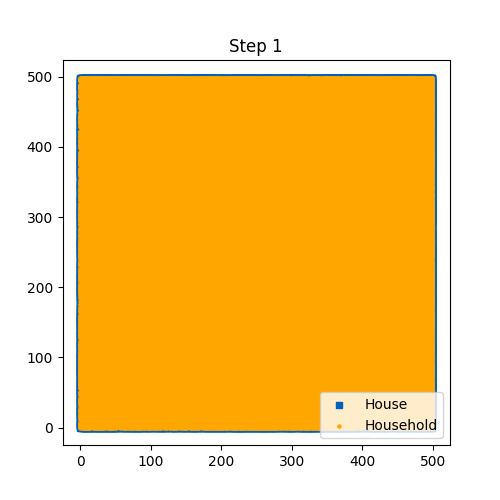

In [48]:
h_dict, hh_dict, _a, _b = load_data(rf"{python_directory}/data/1.json")
figsize_d = 5
plt.figure(figsize=(figsize_d, figsize_d))
plt.title("Step 1")
plt.scatter(h_dict["x"], h_dict["y"], s=20, marker="s", color="#0060BB", label="House")
plt.scatter(hh_dict["x"], hh_dict["y"], s=5, color="#FFA600", label="Household")
plt.legend()
plt.show()

In [49]:
plt.close()